# Spectrum Calculation

In this tutorial, the TA-SC-IVR spectrum is computed from the ro-vibrational trajectory of H2 (`h2_rovib_pi2.npz`) and the monodromy matrix from the previous tutorials.

The spectrum is obtained by
$
I(E) = \frac{1}{t_{\text{tot}}} \left| \int_0^{t_{\text{tot}}} dt \langle \Psi(0) | Q_t, P_t \rangle e^{i \left(\arg C_t + \frac{S_t + E t}{\hbar}\right)} \right|^2,
$

which requires three quantities along the trajectory:

- the overlap $\langle \Psi(0) | Q_t, P_t \rangle$ between the initial state and the coherent state,
- the action $S_t$, and
- the Herman–Kluk pre-factor $C_t$, computed from the monodromy matrix.

Here, only a single trajectory is used to show the procedure. The resulting spectrum consists of discrete peaks, but their positions and intensities are not quantitatively correct. A practical calculation requires the sampling of many trajectories in the phase space, which is shown in the examples.

See [`pyscivr.scivr`](https://tsumura-m.github.io/PySCIVR/pyscivr.scivr.html) for details.

In [1]:
# import necessary libraries

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
 
from pyscivr.basis import get_overlap
from pyscivr.coordinates import InternalCoordinates
from pyscivr.potentials import H2SplinePotential
from pyscivr.save import load_hessian, load_trajectory
from pyscivr.scivr import get_action, get_lagrangian, get_prefactor, get_ta_spectrum_fft
from pyscivr.units import CmInv, FemtoSec, HBar
from pyscivr.variations import make_jacobi_func, make_vari_propagator, propagate_variation, to_internal

## Set system and compute monodromy matrix

The system is the same as in the previous tutorial.

In [2]:
mass = np.array([1.008, 1.008])  # [amu]
r_e = 0.74160392 # equilibrium bond length [Angs]
posi_ref = np.array([[-r_e / 2, 0.0, 0.0], [r_e / 2, 0.0, 0.0]])

coord_const = InternalCoordinates(posi_ref, mass)
coord_const.add_translation()
coord_const.build()

coord_all = InternalCoordinates(posi_ref, mass)
coord_all.add_translation()
coord_all.add_polar(0, 1)
coord_all.add_azimuthal(0, 1)
coord_all.add_bond(0, 1)
coord_all.build()

active_idx = np.array([coord_all.find_coordinate(kind, (0, 1))[0] for kind in ("bond", "polar", "azimuthal")])

traj = load_trajectory("h2_rovib_pi2_traj.npz", coord_const=coord_const)
posi, mome, lam, mu, dt = traj["posi"], traj["mome"], traj["lam"], traj["mu"], traj["dt"]
t_fs = dt / FemtoSec * np.arange(len(posi))

_, hess = load_hessian("h2_rovib_pi2_hess.npz", coord_all, posi, n_step=len(posi))

_, jacobi_rev_func, _, monodromy_func = make_jacobi_func(coord_all, active_idx)
J_rev_init = np.asarray(jacobi_rev_func(posi[0], mome[0]))
vari_propagator = make_vari_propagator(coord_const, dt)
vari = propagate_variation(vari_propagator, posi, mome, lam, mu, hess, J_rev_init)

posi_int, mome_int, mono, symp_err = to_internal(monodromy_func, posi, mome, vari)

Build complete: 3 coordinates
Build complete: 6 coordinates


`to_internal` also returns the positions $Q_t$ and momenta $P_t$ in the physical space (bond length, polar and azimuthal angles), in the order of `active_idx`.

As discussed in the previous tutorial, only the steps where the symplectic condition is satisfied are used.

In [3]:
valid = np.isfinite(symp_err) & (symp_err < 1e-4)

## Overlap with the initial state

We set the initial state $\Psi(0)$ as a coherent state centered at the initial phase-space point of the trajectory.
To target the vibrational ground state, the vibrational momentum is set to 0.

The overlap is the product of the 1D overlaps for each coordinate with its topology
(see [`pyscivr.basis`](https://tsumura-m.github.io/PySCIVR/pyscivr.basis.html) for details).

Here, we set the width parameters as:

| Coordinate | Topology | Width parameter $\gamma$ |
|---|---|---|
| bond length $r$ | `R+` (half line) | $\mu \omega_e / \hbar$ (harmonic ground state) |
| polar angle $\theta$ | `I-` (interval $[0, \pi]$) | $1 / (2 \times 0.2^2)$ $\mathrm{rad}^{-2}$ |
| azimuthal angle $\phi$ | `S1` (circle) | $1 / (2 \times 0.2^2)$ $\mathrm{rad}^{-2}$ |

where $\mu = m_{\text{H}} / 2$ is the reduced mass and $\omega_e = 4401$ $\textrm{cm}^{-1}$ is the harmonic frequency of H2.

In [4]:
posi_ref_int = posi_int[0].copy()
mome_ref_int = mome_int[0].copy()
mome_ref_int[0] = 0.0  # set vibrational momentum to zero for the reference state
 
topologies = [coord_all.find_coordinate(kind, (0, 1))[3] for kind in ("bond", "polar", "azimuthal")]
print("Topologies:", topologies)

omega_e = 4401.0 * CmInv / HBar
gamma = np.array([mass[0] * omega_e / (2 * HBar),
                  1 / (2 * 0.2**2),
                  1 / (2 * 0.2**2)])
 
ovlp = get_overlap(topologies, posi_ref_int, mome_ref_int, posi_int, mome_int, gamma)

Topologies: ['R+', 'I-', 'S1']


## Action

The action $S_t$ is the time integral of the Lagrangian. The energy origin is set to the potential energy at the equilibrium structure, so that the peak positions are measured from the bottom of the potential.

In [5]:
ener_ref = H2SplinePotential().energy(posi_ref)
lag = get_lagrangian(traj["total_energy"], traj["potential_energy"], ener_ref=ener_ref)
action = get_action(lag, dt)

## Pre-factor

The pre-factor $C_t$ is computed from the monodromy matrix, and its phase is tracked continuously along the trajectory (branch tracking of the complex square root). The invalid steps are skipped in the tracking.

In [6]:
pref = get_prefactor(mono, gamma, valid)
print("C_0 =", pref[0])  # should be 1
phase = np.full(len(pref), np.nan)  # NaN at the invalid steps
phase[valid] = np.unwrap(np.angle(pref[valid]))

C_0 = (0.9999999999999999+6.5384800775166165e-18j)


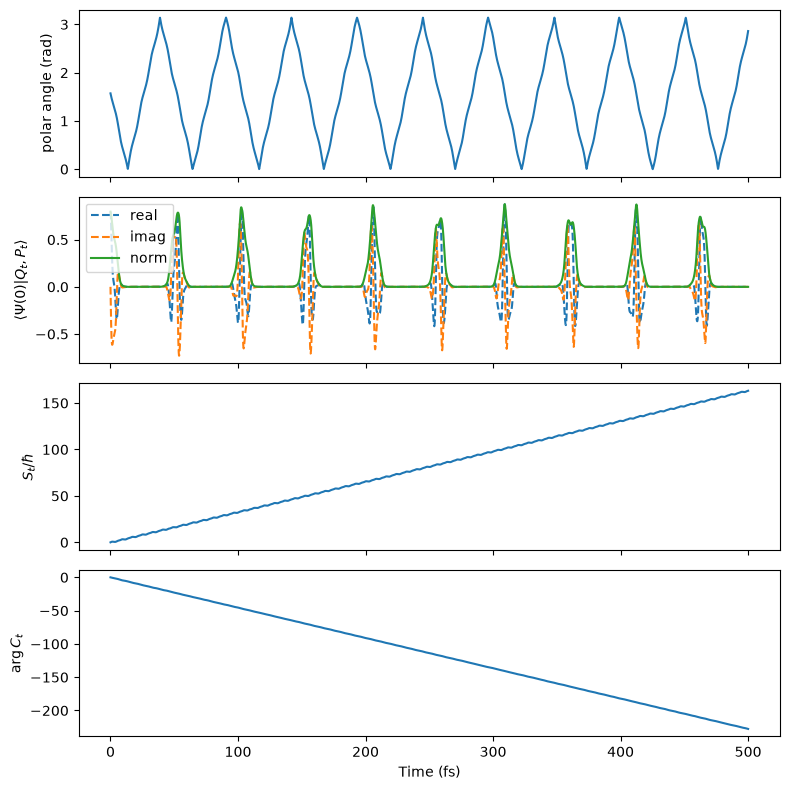

In [7]:
# Plot
fig, ax = plt.subplots(4, 1, figsize=(8, 8), sharex=True)

ax[0].set_ylabel("polar angle (rad)")
ax[0].plot(t_fs[valid], posi_int[valid, 1])
ax[1].set_ylabel(r"$\langle \Psi(0) | Q_t, P_t \rangle$")
ax[1].plot(t_fs[valid], ovlp[valid].real, ls='dashed', label="real")
ax[1].plot(t_fs[valid], ovlp[valid].imag, ls='dashed', label="imag")
ax[1].plot(t_fs[valid], np.sqrt(np.abs(ovlp[valid])**2), label="norm")
ax[1].legend()

ax[2].plot(t_fs[valid], action[valid] / HBar)
ax[2].set_ylabel(r"$S_t / \hbar$")
ax[3].plot(t_fs[valid], phase[valid])
ax[3].set_ylabel(r"$\arg C_t$")
ax[3].set_xlabel("Time (fs)")
plt.tight_layout()
plt.show()

## Spectrum

The spectrum is computed by the zero-padded FFT. The grid spacing is $2 \pi \hbar / (n_{\text{fft}} \Delta t)$, while the intrinsic resolution is limited by the total time, $2 \pi \hbar / t_{\text{tot}}$.

The computed result is compared with the Dunham expansion references.

Grid spacing (cm^-1): 0.64
Peaks (cm^-1): [2623.8 3272.7 3921.7 4570.  5218.9 5867.9 6518.1]


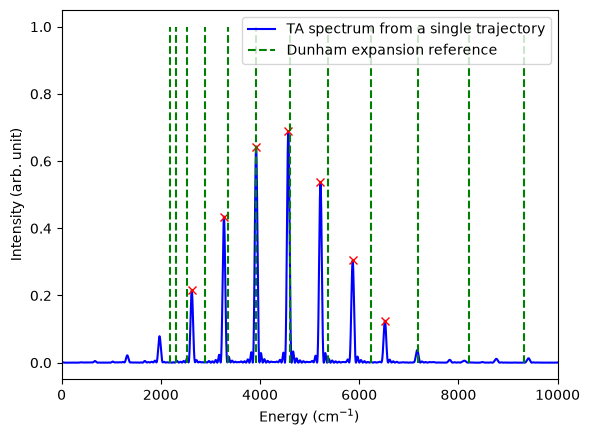

In [8]:
# Reference energy levels (Dunham expansion)
def f(x, B, D, H, L):
    return B*x*(x+1)-D*x*x*(x+1)*(x+1)+H*(x**3)*((x+1)**3)+L*(x**4)*((x+1)**4)

# Dunham expansion coefficients for H2 vibrational ground state
# D. E. Jennings and J. W. Brault, "The ground state of molecular hydrogen", Journal of Molecular Spectroscopy 102, 265–272 (1983).
B = 59.334547
D = 0.0456821
H = 4.8542e-5
L = -5.411e-8

zpe = 2183.0  # zero-point energy [cm^-1]
analytical_energies = [f(n, B, D, H, L) + zpe for n in range(20)]

ener_grid, spec = get_ta_spectrum_fft(pref, ovlp, action, dt, n_fft=2**19, valid=valid)
print(f"Grid spacing (cm^-1): {np.round((ener_grid[1]- ener_grid[0]) / CmInv, 2)}")

peaks, _ = find_peaks(spec, height=0.1, prominence=0.05, distance=10)
print(f"Peaks (cm^-1): {np.round(ener_grid[peaks] / CmInv, 1)}")
 
plt.plot(ener_grid / CmInv, spec, color='blue', label="TA spectrum from a single trajectory")
plt.plot(ener_grid[peaks] / CmInv, spec[peaks], "x", color="red")
plt.vlines(analytical_energies, 0, 1.0, color="green", ls="dashed", label="Dunham expansion reference")

plt.xlim(0, 10000)
plt.xlabel("Energy (cm$^{-1}$)")
plt.ylabel("Intensity (arb. unit)")
plt.legend()
plt.show()

- The spectrum of a single trajectory consists of discrete peaks.
- The peaks agree with the reference levels near the energy of the trajectory itself
  (about 4000 $\textrm{cm}^{-1}$ above the potential minimum), while they deviate away from it.
- This property is exploited in few-trajectory approaches such as the multiple coherent (MC) SC-IVR,
  in which a trajectory with an energy close to each target level is used to obtain that level
  [J. Chem. Phys. **130**, 234113 (2009); J. Phys. Chem. Lett. **4**, 3407 (2013)].
- To reproduce the whole spectrum, many trajectories must be sampled in the phase space around the initial state.

The following tutorials show practical calculations with the phase-space sampling.